In [125]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#Load CSV File
df = pd.read_csv("House Prediction.csv")
display(df.head())


,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
0,2014-05-02 00:00:00,313000.0,3.0,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,USA
1,2014-05-02 00:00:00,2384000.0,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,USA
2,2014-05-02 00:00:00,342000.0,3.0,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,USA
3,2014-05-02 00:00:00,420000.0,3.0,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0,857 170th Pl NE,Bellevue,WA 98008,USA
4,2014-05-02 00:00:00,550000.0,4.0,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992,9105 170th Ave NE,Redmond,WA 98052,USA


# Data Understanding

In [126]:
#Data Understanding
print(df.shape)
print(df.info())
print(df.describe())
print(df.isnull().sum())
print(df.duplicated().sum())

(4600, 18)
<class 'pandas.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           4600 non-null   str    
 1   price          4600 non-null   float64
 2   bedrooms       4600 non-null   float64
 3   bathrooms      4600 non-null   float64
 4   sqft_living    4600 non-null   int64  
 5   sqft_lot       4600 non-null   int64  
 6   floors         4600 non-null   float64
 7   waterfront     4600 non-null   int64  
 8   view           4600 non-null   int64  
 9   condition      4600 non-null   int64  
 10  sqft_above     4600 non-null   int64  
 11  sqft_basement  4600 non-null   int64  
 12  yr_built       4600 non-null   int64  
 13  yr_renovated   4600 non-null   int64  
 14  street         4600 non-null   str    
 15  city           4600 non-null   str    
 16  statezip       4600 non-null   str    
 17  country        4600 non-null   str    
dtypes: float

In [127]:
df = df[df['price']<10000000]

# EDA

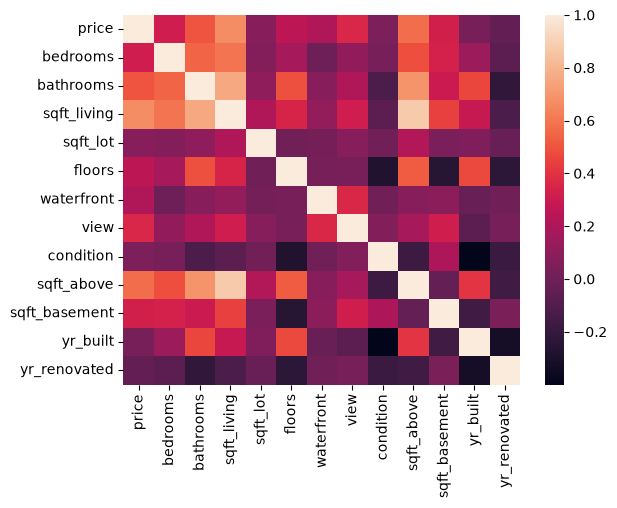

In [128]:
plt.Figure(figsize=(10,6))
sns.heatmap(df.corr(numeric_only=True))
plt.show()

<Axes: xlabel='sqft_above', ylabel='price'>

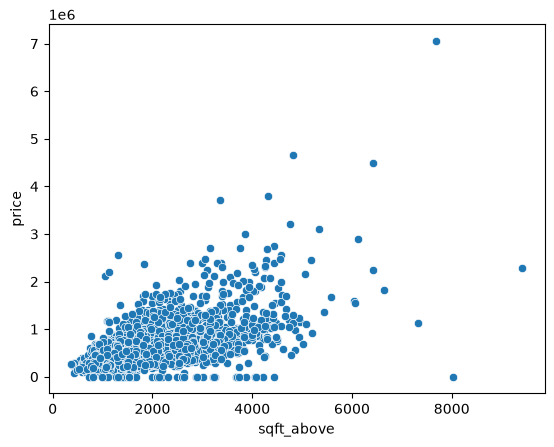

In [129]:
sns.scatterplot(x='sqft_above',y='price', data=df)

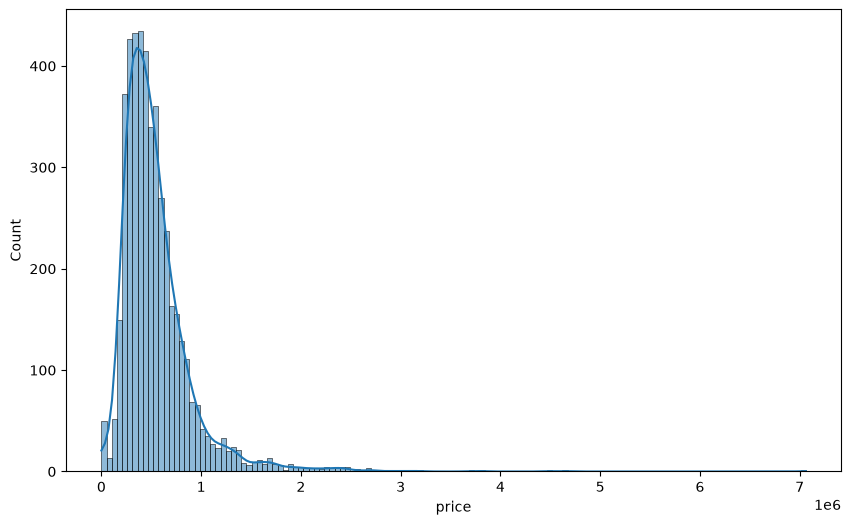

In [130]:
plt.figure(figsize=(10,6))
sns.histplot(df['price'], kde=True)
plt.show()

Text(0.5, 0, 'log_price')

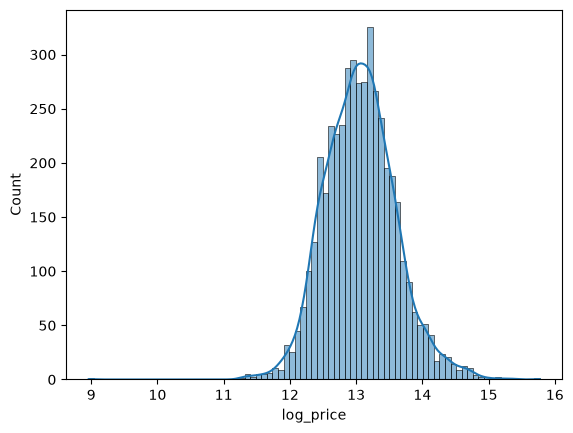

In [131]:
df = df[df['price']>0]
sns.histplot(np.log1p(df['price']), kde=True)
plt.xlabel('log_price')

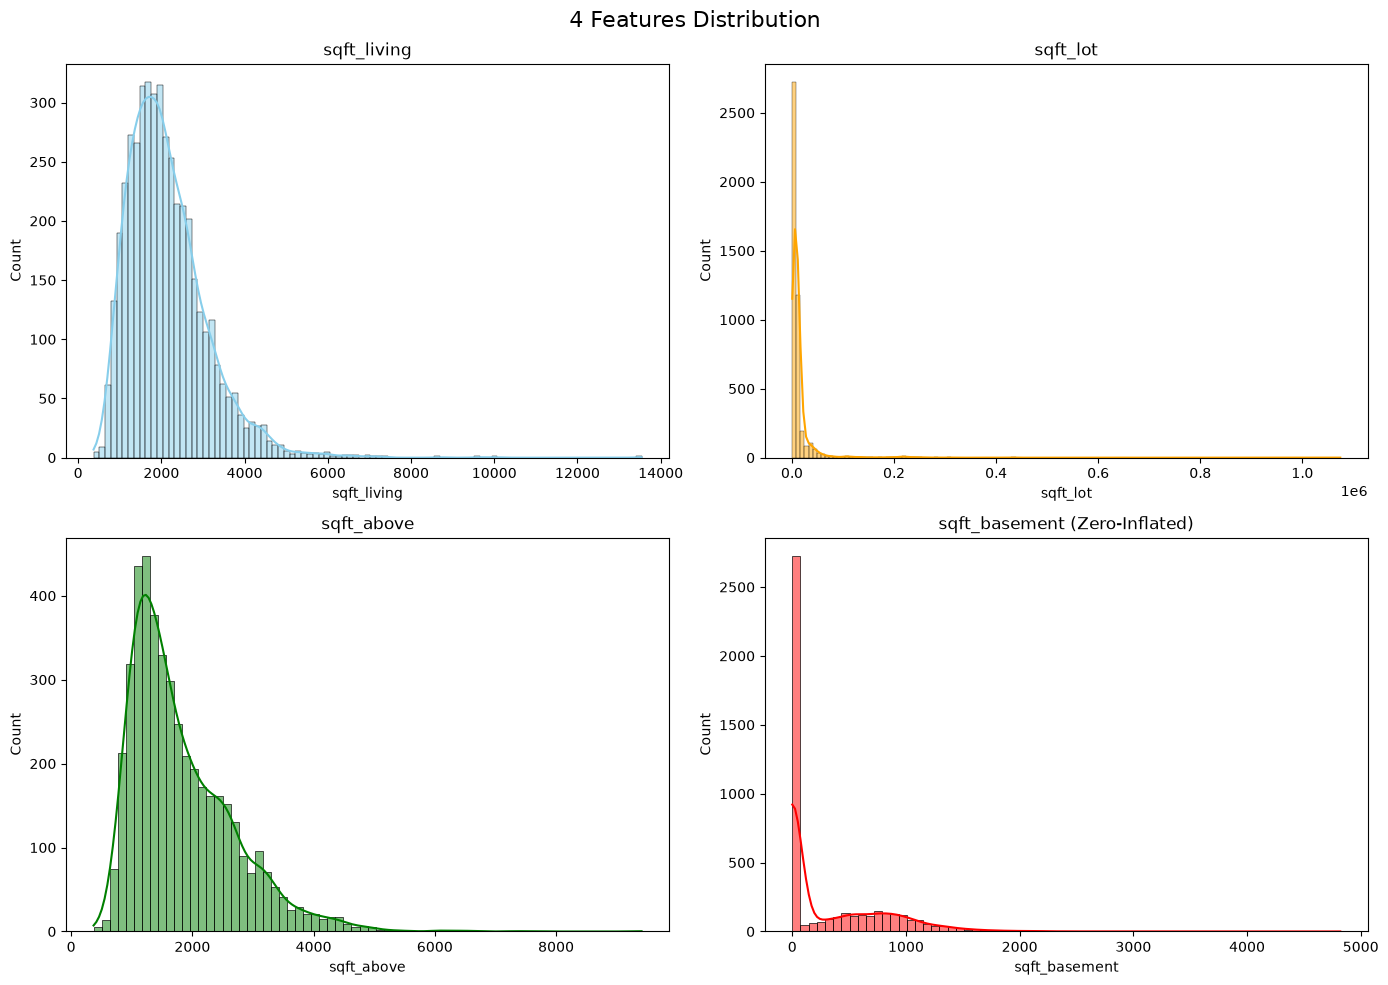

In [132]:
import matplotlib.pyplot as plt
import seaborn as sns


fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('4 Features Distribution', fontsize=16)

# Graph 1
sns.histplot(df['sqft_living'], kde=True, ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title('sqft_living')
axes[0, 0].set_xlabel('sqft_living')
axes[0, 0].set_ylabel('Count')

# Graph 2
sns.histplot(df['sqft_lot'], kde=True, ax=axes[0, 1], color='orange')
axes[0, 1].set_title('sqft_lot')
axes[0, 1].set_xlabel('sqft_lot')

# Graph 3
sns.histplot(df['sqft_above'], kde=True, ax=axes[1, 0], color='green')
axes[1, 0].set_title('sqft_above')
axes[1, 0].set_xlabel('sqft_above')

# Graph 4
sns.histplot(df['sqft_basement'], kde=True, ax=axes[1, 1], color='red')
axes[1, 1].set_title('sqft_basement (Zero-Inflated)')
axes[1, 1].set_xlabel('sqft_basement')

plt.tight_layout()
plt.show()

In [133]:
#Outliers
num_features = df.select_dtypes(include='number') #int64 or float 64
Q1 = num_features.quantile(0.25)
Q3 = num_features.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = ((num_features < lower_bound) | (num_features > upper_bound))
print(outliers.sum())

price            238
bedrooms         115
bathrooms        130
sqft_living      128
sqft_lot         540
floors             0
waterfront        30
view             448
condition          6
sqft_above       111
sqft_basement     83
yr_built           0
yr_renovated       0
dtype: int64


# Feature Engeering

In [134]:
print(df.columns)

Index(['date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot',
       'floors', 'waterfront', 'view', 'condition', 'sqft_above',
       'sqft_basement', 'yr_built', 'yr_renovated', 'street', 'city',
       'statezip', 'country'],
      dtype='str')


In [135]:
(df['price']>10000000).drop

<bound method Series.drop of 0       False
1       False
2       False
3       False
4       False
        ...  
4595    False
4596    False
4597    False
4598    False
4599    False
Name: price, Length: 4549, dtype: bool>

In [136]:
df['date'] = pd.to_datetime(df['date'])
df['month_sold'] = df['date'].dt.month
df['year_sold'] = df['date'].dt.year

In [137]:
df['yr_renovated'] = np.where(df['yr_renovated']==0,df['yr_built'],df['yr_renovated'])

In [138]:
df['city'].value_counts().index[:12].tolist()

['Seattle',
 'Renton',
 'Bellevue',
 'Redmond',
 'Kirkland',
 'Issaquah',
 'Kent',
 'Auburn',
 'Sammamish',
 'Federal Way',
 'Shoreline',
 'Woodinville']

In [139]:
top_cities = ['Seattle',
 'Renton',
 'Bellevue',
 'Redmond',
 'Kirkland',
 'Issaquah',
 'Kent',
 'Auburn',
 'Sammamish',
 'Federal Way',
 'Shoreline',
 'Woodinville']

def Grouped_Countries(a):
    if a in  top_cities:
        return a
    else:
        return 'other'

df['grouped_cities'] = df['city'].apply(Grouped_Countries)

In [140]:
print(df['grouped_cities'].value_counts())

grouped_cities
Seattle        1560
other           898
Renton          291
Bellevue        281
Redmond         235
Kirkland        187
Issaquah        186
Kent            183
Auburn          175
Sammamish       171
Federal Way     145
Shoreline       123
Woodinville     114
Name: count, dtype: int64


In [141]:
print(df.columns)

Index(['date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot',
       'floors', 'waterfront', 'view', 'condition', 'sqft_above',
       'sqft_basement', 'yr_built', 'yr_renovated', 'street', 'city',
       'statezip', 'country', 'month_sold', 'year_sold', 'grouped_cities'],
      dtype='str')


In [142]:
display(df['statezip'].value_counts())

statezip
WA 98103    148
WA 98052    135
WA 98117    132
WA 98115    129
WA 98006    109
           ... 
WA 98047      6
WA 98288      3
WA 98050      2
WA 98354      2
WA 98068      1
Name: count, Length: 77, dtype: int64

In [143]:
print(df.columns)

Index(['date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot',
       'floors', 'waterfront', 'view', 'condition', 'sqft_above',
       'sqft_basement', 'yr_built', 'yr_renovated', 'street', 'city',
       'statezip', 'country', 'month_sold', 'year_sold', 'grouped_cities'],
      dtype='str')


In [144]:
skewed_col = ['sqft_basement', 'sqft_above', 'sqft_living', 'sqft_lot']

normal_col = ['bedrooms', 'bathrooms',
       'floors', 'waterfront', 'view', 'condition',
       'yr_built', 'yr_renovated']

ohe_col = ['grouped_cities','statezip']

feature_col = normal_col + skewed_col + ohe_col

# Train-Test-Split

In [145]:
from sklearn.model_selection import train_test_split

x = df[feature_col]
y = df['price']

x_train, x_test, y_train, y_test = train_test_split(
    x,y,test_size=0.2,random_state=42
)

# Pipeline

In [146]:
from sklearn import pipeline
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer


#Skewed Features
skew_pipeline = Pipeline(steps=[
    ('log_transform', FunctionTransformer(np.log1p)),
    ('scaler', StandardScaler())
])

#normal columns
normal_pipeline = Pipeline(steps=[
    ('normal_col',StandardScaler())
])

# Ordinal Pipeline
ohe_pipeline = Pipeline(steps=[
    ('encode', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('Skewed_Pipeline',skew_pipeline,skewed_col),
    ('normal_col',normal_pipeline,normal_col),
    ('ohe_pipeline',ohe_pipeline,ohe_col)
])

# Linear Regresson

In [147]:
from sklearn.linear_model import LinearRegression
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

lr_pipeline = Pipeline(steps=[
    ('preprocessor',preprocessor),
    ('reggressor',LinearRegression())
])

model = TransformedTargetRegressor(
    regressor=lr_pipeline,
    func=np.log1p,
    inverse_func=np.expm1
)

model.fit(x_train, y_train)
lr_preds = model.predict(x_test)
lr_preds_train = model.predict(x_train)

lr_r2_testing = r2_score(y_test, lr_preds)
lr_t2_training = r2_score(y_train,lr_preds_train)

print(f'Accuracy of Training: {lr_t2_training}')
print(f'Accuracy of Testing: {lr_t2_training}')

lr_mae_testing = mean_absolute_error(y_test,lr_preds)
lr_mae_training = mean_absolute_error(y_train,lr_preds_train)

print(f'MAE of Training: {lr_mae_training}')
print(f'MAE of Testing: {lr_mae_testing}')

Accuracy of Training: 0.823177473390344
Accuracy of Testing: 0.823177473390344
MAE of Training: 80548.76606405737
MAE of Testing: 94361.21981086384


# RandomForestRagressor

In [148]:
from sklearn.ensemble import RandomForestRegressor

rf_pipeline = Pipeline(steps=[
    ('preprocessor',preprocessor),
    ('RandomForestRegressor',RandomForestRegressor(random_state=42))
])

model2 = TransformedTargetRegressor(
    regressor=rf_pipeline,
    func=np.log1p,
    inverse_func=np.expm1
)

model2.fit(x_train,y_train)
rf_predict = model2.predict(x_test)
rf_predict_train = model2.predict(x_train)

rf_r2_test = r2_score(y_test,rf_predict)
rf_r2_train = r2_score(y_train,rf_predict_train)

rf_mae_test = mean_absolute_error(y_test,rf_predict)
rf_mae_train = mean_absolute_error(y_train,rf_predict_train)

print(f'R2 Testing Score: {rf_r2_test}')
print(f'R2 Training Score: {rf_r2_train}')

print(f'MAE Testing Score: {rf_mae_test}')
print(f'MAE Training Score: {rf_mae_train}')

R2 Testing Score: 0.7010002256999409
R2 Training Score: 0.9320852727893754
MAE Testing Score: 114516.90025877143
MAE Training Score: 39274.00331614047


# HyperParameterTunning

In [149]:
from sklearn.model_selection import RandomizedSearchCV

param_grid = {
    'regressor__RandomForestRegressor__n_estimators': [200, 300, 500],

    'regressor__RandomForestRegressor__max_depth': [10, 15, 20, 25, 30, None],

    'regressor__RandomForestRegressor__min_samples_split': [2, 3, 5, 8],

    'regressor__RandomForestRegressor__min_samples_leaf': [1, 2, 3, 4],

    'regressor__RandomForestRegressor__max_features': [0.6, 0.8, 1.0]
}

random_search = RandomizedSearchCV(
    estimator = model2,
    param_distributions = param_grid,
    cv = 5,
    scoring = 'r2',
    random_state=42,
    n_jobs=-1
)

random_search.fit(x_train,y_train)

print(random_search.best_params_)

{'regressor__RandomForestRegressor__n_estimators': 500, 'regressor__RandomForestRegressor__min_samples_split': 3, 'regressor__RandomForestRegressor__min_samples_leaf': 1, 'regressor__RandomForestRegressor__max_features': 0.8, 'regressor__RandomForestRegressor__max_depth': 25}


In [150]:
rf_best_pipeline = random_search.best_estimator_
rf_best_preds = rf_best_pipeline.predict(x_test)

print(f"r2 score  for random forest after hyperparameter tunning {r2_score(y_test,rf_best_preds)}")
print(f"MAE score after hyperparameter tunning: {mean_absolute_error(y_test,rf_best_preds)}")

r2 score  for random forest after hyperparameter tunning 0.7036228616875129
MAE score after hyperparameter tunning: 114068.27837424095


In [151]:
from xgboost import XGBRegressor

xgb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('XGBRegressor', XGBRegressor(
        random_state=42,
        n_estimators=500,
        learning_rate=0.05,
        max_depth=6,
        min_child_weight=3,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1,
        objective='reg:squarederror',
        n_jobs=-1
    ))
])

xgb_model = TransformedTargetRegressor(
    regressor=xgb_pipeline,
    func=np.log1p,
    inverse_func=np.expm1
)

xgb_model.fit(x_train, y_train)

xgb_predict = xgb_model.predict(x_test)
xgb_predict_train = xgb_model.predict(x_train)

print('R2 Testing:', r2_score(y_test, xgb_predict))
print('R2 Training:', r2_score(y_train, xgb_predict_train))

print('MAE Testing:', mean_absolute_error(y_test, xgb_predict))
print('MAE Training:', mean_absolute_error(y_train, xgb_predict_train))

R2 Testing: 0.7750154955086441
R2 Training: 0.9508962025146217
MAE Testing: 100510.66802808901
MAE Training: 45967.17526077948


# XGBoost Hyperpararmeter Tunning

In [152]:
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBRegressor
from scipy.stats import randint, uniform

param_grid = {
    'regressor__XGBRegressor__n_estimators': [300, 500, 700, 1000],
    'regressor__XGBRegressor__learning_rate': [0.01, 0.03, 0.05, 0.1],
    'regressor__XGBRegressor__max_depth': [3, 4, 5, 6, 7, 8, 10],
    'regressor__XGBRegressor__min_child_weight': [1, 2, 3, 5, 7],
    'regressor__XGBRegressor__subsample': [0.6, 0.7, 0.8, 0.9, 1.0],
    'regressor__XGBRegressor__colsample_bytree': [0.6, 0.7, 0.8, 0.9, 1.0],
    'regressor__XGBRegressor__gamma': [0, 0.1, 0.2, 0.5, 1],
    'regressor__XGBRegressor__reg_alpha': [0, 0.01, 0.1, 1],
    'regressor__XGBRegressor__reg_lambda': [1, 2, 5, 10]
}

xgb_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_grid,
    n_iter=50,
    scoring='neg_mean_absolute_error',
    cv=5,
    verbose=2,
    random_state=42,
    n_jobs=-1
)

xgb_search.fit(x_train, y_train)

print("Best Parameters:", xgb_search.best_params_)

print("Best CV MAE:", -xgb_search.best_score_)

best_model = xgb_search.best_estimator_

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best Parameters: {'regressor__XGBRegressor__subsample': 0.9, 'regressor__XGBRegressor__reg_lambda': 10, 'regressor__XGBRegressor__reg_alpha': 0.1, 'regressor__XGBRegressor__n_estimators': 1000, 'regressor__XGBRegressor__min_child_weight': 7, 'regressor__XGBRegressor__max_depth': 3, 'regressor__XGBRegressor__learning_rate': 0.1, 'regressor__XGBRegressor__gamma': 0, 'regressor__XGBRegressor__colsample_bytree': 0.7}
Best CV MAE: 87627.48856555842


In [153]:
from sklearn.metrics import mean_absolute_error, r2_score

y_pred = best_model.predict(x_test)

print("R2 Score:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))

R2 Score: 0.7894403174887495
MAE: 97562.68378243186


In [157]:
xgb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('XGBRegressor', XGBRegressor(
        subsample = 0.9, 
        reg_lambda = 10, 
        reg_alpha = 0.1, 
        n_estimators = 1000, 
        min_child_weight = 7, 
        max_depth = 3, 
        learning_rate = 0.1, 
        gamma = 0, 
        colsample_bytree = 0.7
    ))
])

xgb_model = TransformedTargetRegressor(
    regressor=xgb_pipeline,
    func=np.log1p,
    inverse_func=np.expm1
)

xgb_model.fit(x_train, y_train)

xgb_predict = xgb_model.predict(x_test)
xgb_predict_train = xgb_model.predict(x_train)

print('R2 Testing:', r2_score(y_test, xgb_predict))
print('R2 Training:', r2_score(y_train, xgb_predict_train))

print('MAE Testing:', mean_absolute_error(y_test, xgb_predict))
print('MAE Training:', mean_absolute_error(y_train, xgb_predict_train))

R2 Testing: 0.7869343824708163
R2 Training: 0.9092949281066307
MAE Testing: 98891.59951872088
MAE Training: 60061.79205974272


In [159]:
import joblib
joblib.dump(xgb_model,'House_Price_Prediction.pkl')

['House_Price_Prediction.pkl']